# JavaScript Proxy Objects and Reflect

This course covers the JavaScript `Proxy` object and the `Reflect` API — how they work under the hood, how to write handlers with traps, and how to apply them to real-world problems like validation, auditing, iteration control, and function throttling. Requires ECMAScript 2015 (ES6) or later.

## Table of Contents

1. [Module 01: JavaScript's Proxy Object](#module-01-javascripts-proxy-object)
2. [Module 02: Iteration with Proxies](#module-02-iteration-with-proxies)
3. [Module 03: Proxies in Action](#module-03-proxies-in-action)
4. [Module 04: Simplifying Proxies with Reflect](#module-04-simplifying-proxies-with-reflect)

In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

def render_diagram(image_path, width=900):
    data = base64.b64encode(Path(image_path).read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))

## Module 01: JavaScript's Proxy Object

_Covers how JavaScript objects actually work internally, why Proxies exist, what can be wrapped, and how to implement basic traps._

### JavaScript Objects Under the Hood

Every JavaScript object — including arrays, functions, dates, and plain `{}` literals — is internally represented as a collection of named properties. When you write `customer.firstName`, the engine looks up `"firstName"` in that property array and returns the associated value. Every read is effectively a **get**, every write a **set**, and every method call a **get** followed by an **apply**.


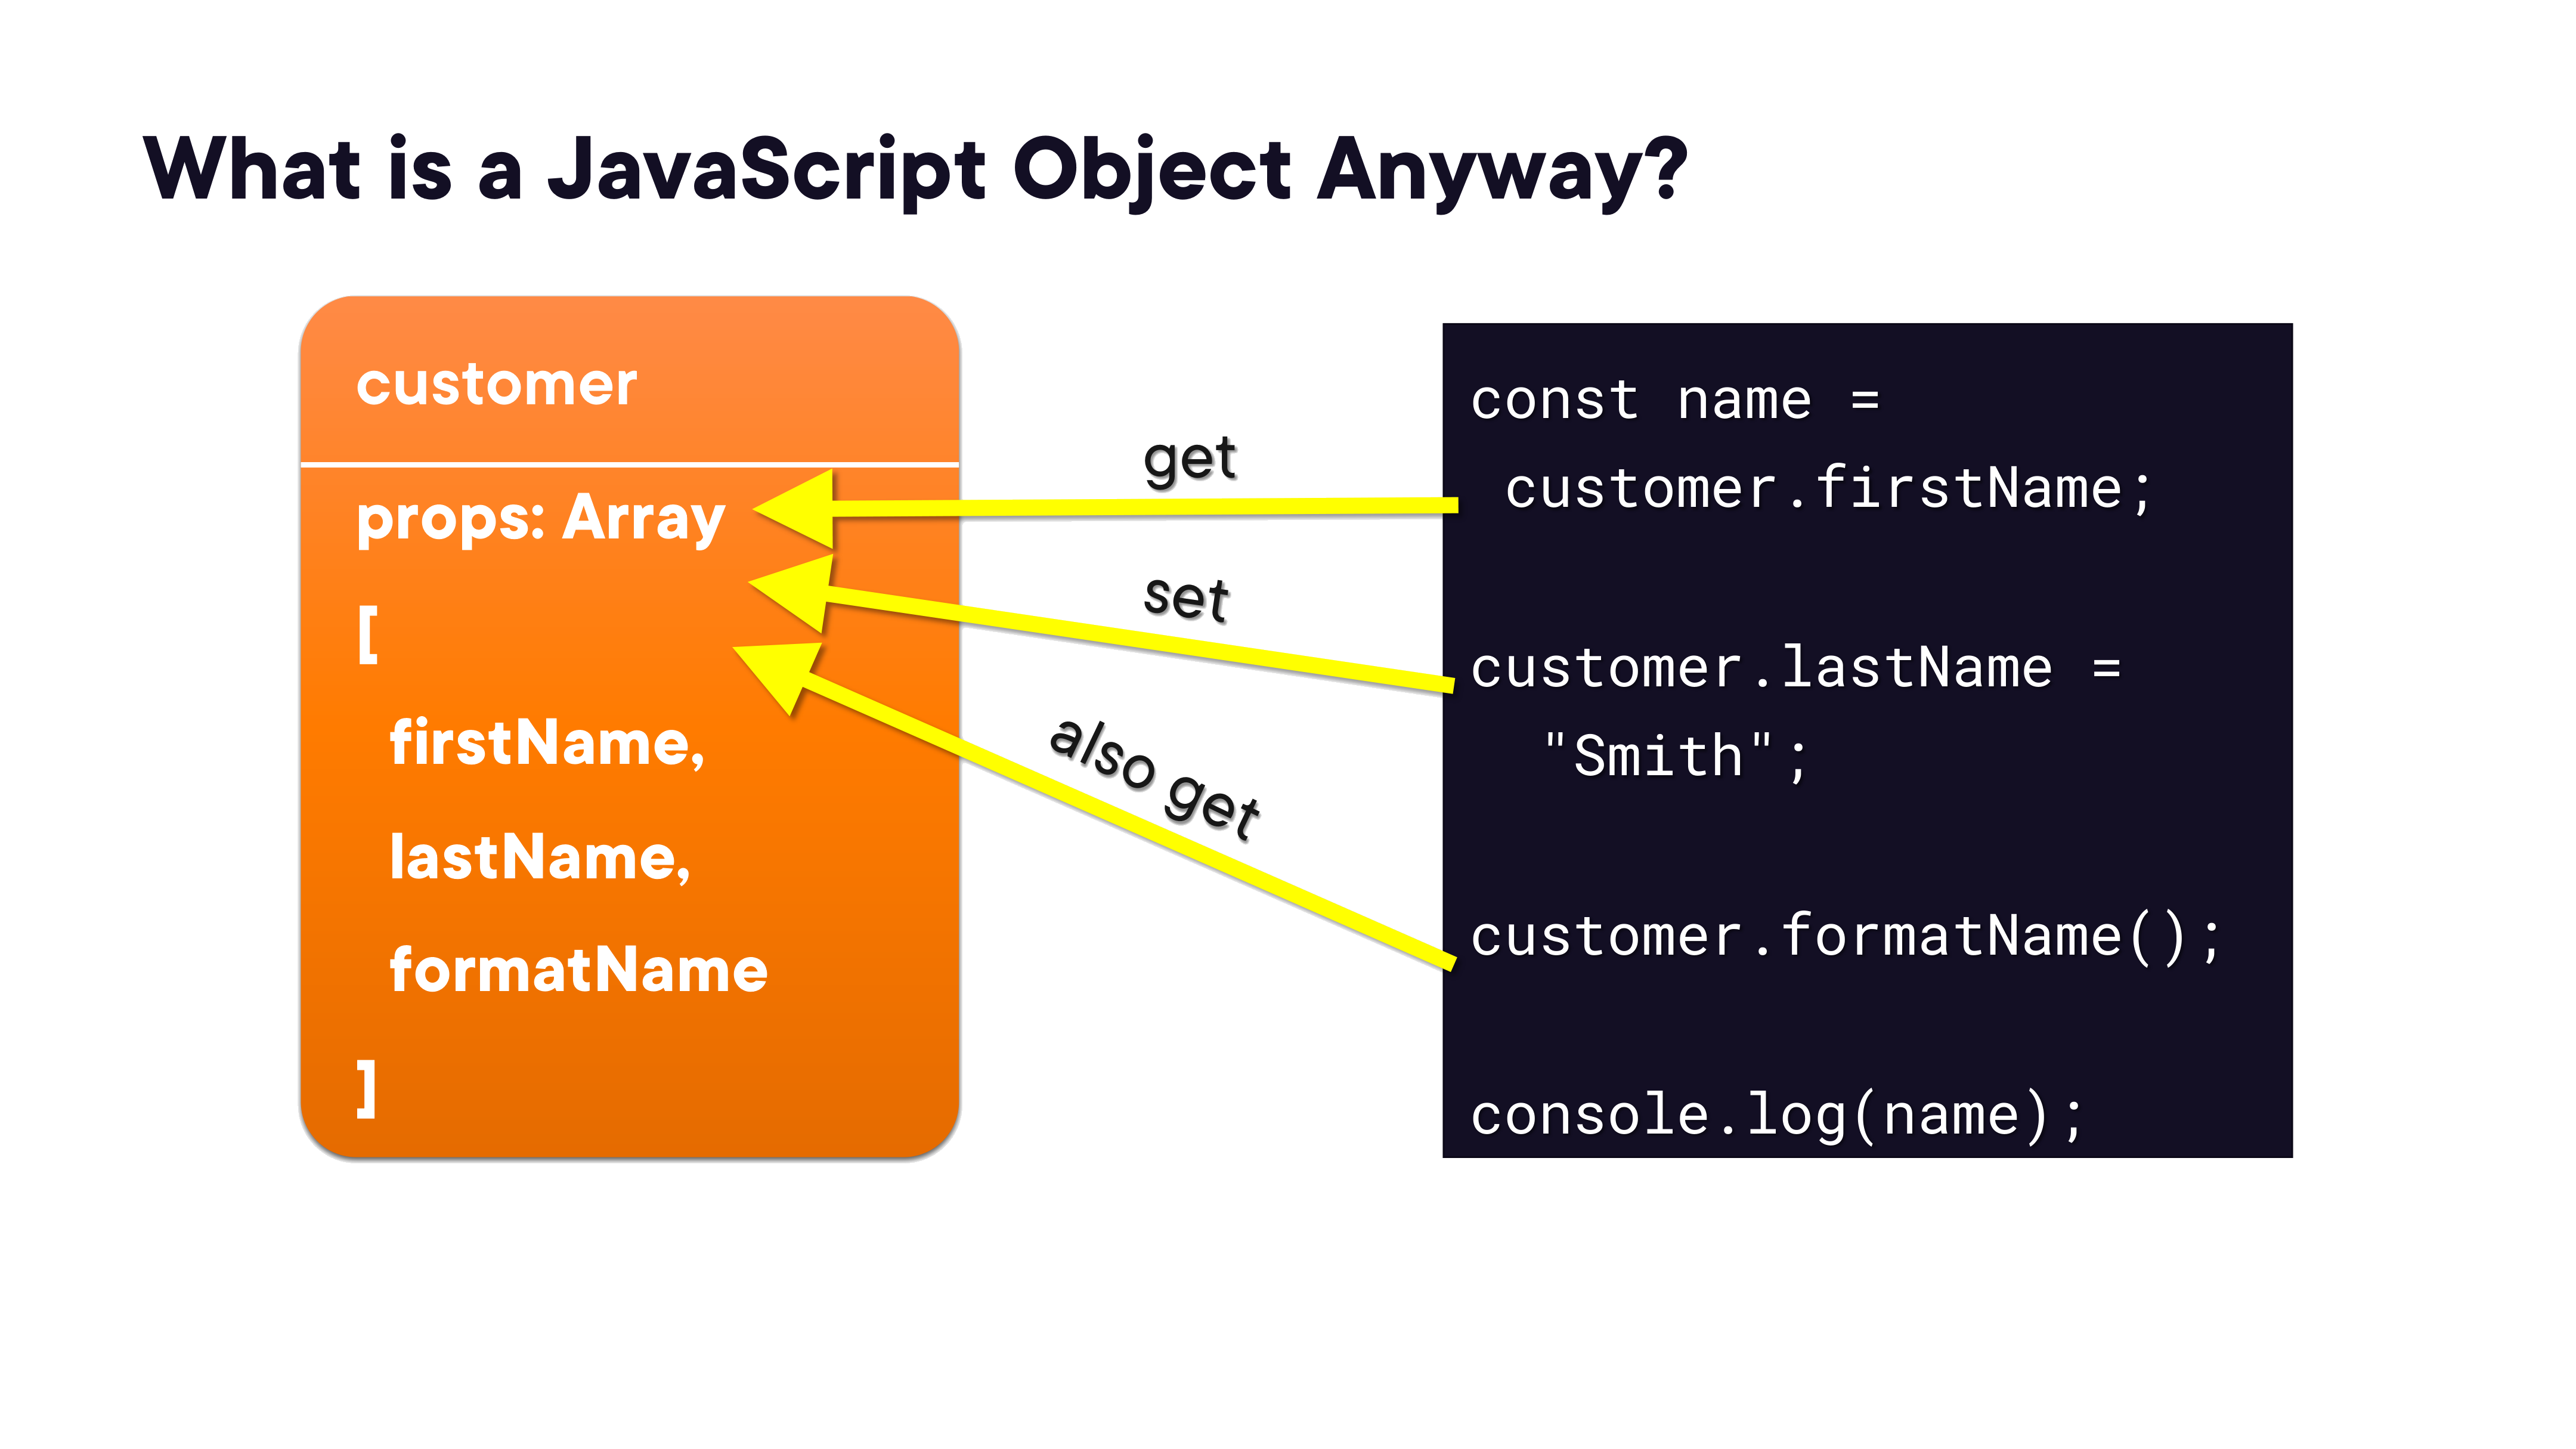

In [2]:
render_diagram(Path("assets/01-javascript-object-operations.png"))

### What is a Proxy?

A **Proxy** wraps any object and intercepts operations on it through a **handler** object. The handler acts as a façade: every get, set, or function call passes through handler traps before reaching (or after returning from) the underlying target.

```javascript
const customer = { firstName: "", lastName: "", formatName() {} };

// Without a Proxy: operations go directly to customer
const name = customer.firstName;

// With a Proxy: operations pass through the handler first
const proxy = new Proxy(customer, handler);
const name = proxy.firstName; // handler.get fires first
```


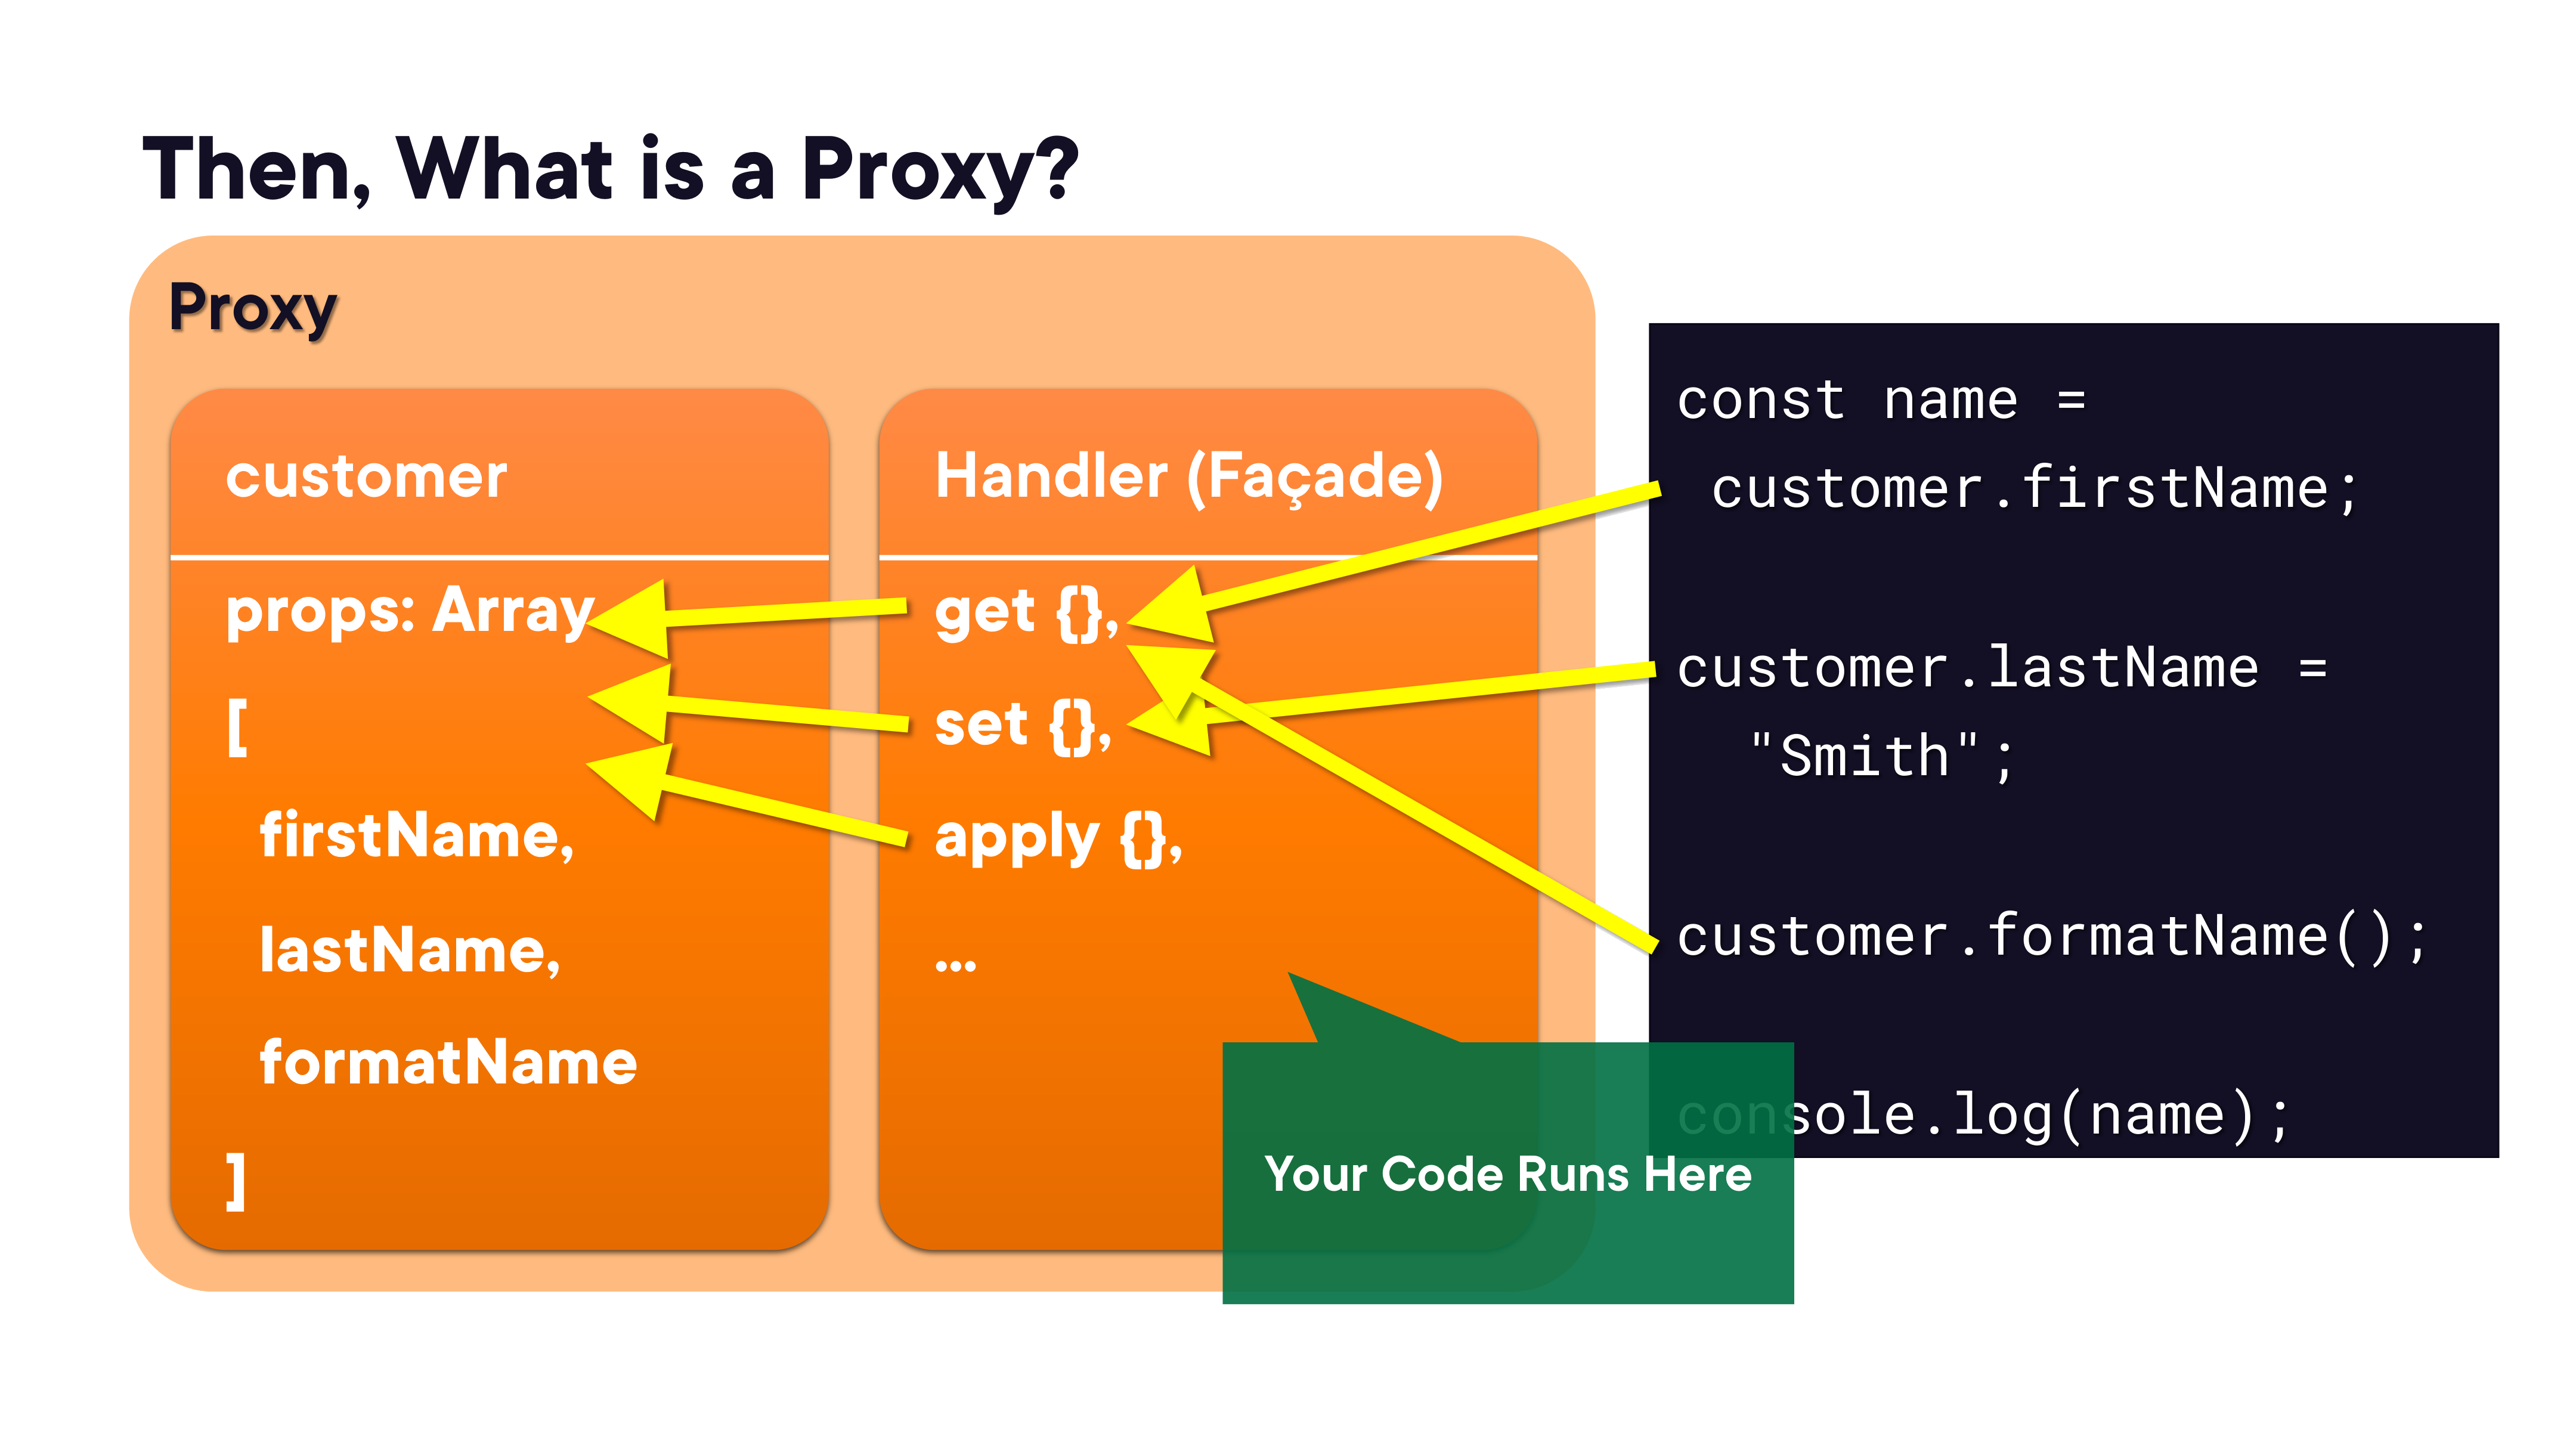

In [3]:
render_diagram(Path("assets/02-proxy-facade-pattern.png"))

### Creating a Proxy

The `Proxy` constructor takes two arguments: the **target** object and a **handler**. Both are required. An empty handler `{}` means "pass everything through unchanged".

```javascript
const product = { name: "", price: 0 };

// Empty handler — fully transparent proxy
const proxy = new Proxy(product, {});
proxy.name = "Nails";

console.log(proxy.name);   // "Nails"
console.log(product.name); // "Nails" — the underlying object is mutated
```

The proxy and the target share state. Writing through the proxy modifies the target directly.

### What Can Be Wrapped by a Proxy?

Only **objects** can be wrapped. Primitives — numbers, strings, booleans, `null`, `undefined`, `Symbol` values — cannot be proxied.

```javascript
// ✗ Cannot proxy — these are primitives
const number = 25;
const final  = false;
const name   = "One";
const value  = null;
let   item;               // undefined
const id     = Symbol(1500);

// ✓ Can proxy — all of these are objects
const invoice  = { number };
const items    = [invoice];
const saleDate = new Date();
const aSet     = new Set();
const aMap     = new Map();
```

Arrays, dates, sets, maps, and class instances are all valid proxy targets.

### Traps

A **trap** is a method on the handler that intercepts a specific operation. Traps are opt-in: you only define the ones you care about. Un-trapped operations fall through to the target unchanged.

Common use-cases for traps:
- **Validation** — reject invalid property values before they are set
- **Change notification** — emit events when properties change (the basis of reactive frameworks)
- **Auditing** — log reads and writes for debugging or compliance
- **Reactivity** — the mechanism behind Vue 3's reactivity system

### The `get` Trap

The `get` trap fires on every property read. Its signature is `(target, prop, receiver)`. The return value becomes what the caller sees.

```javascript
const person = { name: "Shawn" };

const handler = {
  get(target, prop) {
    const val = target[prop];
    if (typeof val === "string") {
      return val.toUpperCase(); // transform on read
    }
    return val;
  }
};

const proxy = new Proxy(person, handler);
console.log(proxy.name); // "SHAWN" — uppercased by the trap
```

The trap intercepts the read; `person.name` is still `"Shawn"` unchanged.

### The `apply` Trap

The `apply` trap fires when the proxied **function** is called. Its signature is `(target, thisArg, args)`.

```javascript
function out(msg) {
  console.log(msg);
}

const handler = {
  apply(target, thisArg, args) {
    // intercept the call, then delegate
    target.apply(thisArg, args);
  }
};

const proxy = new Proxy(out, handler);
proxy("hello"); // handler.apply fires, then the real out() runs
```

`apply` is the trap for function invocation — it only makes sense on a function target.

### Module 01 Summary

> Proxies are surrogates for objects. Traps are object-level middleware for operations. You can proxy anything that is an `object` type — primitives are not supported.

---

## Module 02: Iteration with Proxies

_How to intercept iteration over arrays and object keys using the `get`, `ownKeys`, and `has` traps, and how to wrap nested objects by returning proxies from a trap._

### Proxying Arrays

Arrays are objects, so the same `Proxy` API applies. One important constraint: **a proxy on an array does not automatically proxy its items** — the proxy only intercepts direct operations on the array itself (length reads, index reads/writes, `push` calls via the `get`+`apply` chain). To proxy items too, you must return proxied items from the `get` trap.

When intercepting array operations you often need multiple traps, because iteration triggers both index reads and `.length` reads internally.

```javascript
const items = ["alpha", "beta", "gamma"];

const handler = {
  get(target, prop) {
    console.log(`get: ${prop}`);
    return target[prop];
  },
  set(target, prop, value) {
    console.log(`set: ${prop} = ${value}`);
    target[prop] = value;
    return true; // set trap must return true on success
  }
};

const proxy = new Proxy(items, handler);

// Iterating triggers many internal get/set operations:
for (const item of proxy) {
  console.log(item);
}
```

> **Note:** The `set` trap must return `true` (or a truthy value). Returning `false` or `undefined` causes a `TypeError` in strict mode.

### Demo: Handling Array Iteration with a Proxy

See [`01-proxy-object-demos/`](01-proxy-object-demos/) for the full project. The `before/` directory shows plain array iteration; `after/` adds a proxy that intercepts each index access to demonstrate how many internal operations a simple `for...of` loop triggers.

```javascript
// from 01-proxy-object-demos/after/index.js (representative excerpt)
const handler = {
  set(target, prop, val) {
    out(`Setting: ${prop} - ${val}`);
    target[prop] = val;
    return true;
  },
  get(target, prop) {
    out(`Getting: ${prop}`);
    const value = target[prop];
    if (typeof value === "string") {
      return `"${value}"`;
    }
    return value;
  }
};

const custProxy = new Proxy(customer, handler);
custProxy.firstName = "Shawn"; // triggers set trap
out(custProxy.firstName);       // triggers get trap, returns quoted string
```

### Intercepting Object Key Enumeration

To intercept `for...in`, `Object.keys()`, and spread operations, use the **`ownKeys`** trap. It must return an array of property name strings or Symbols.

```javascript
const order = { orderId: 1, _secret: "internal", total: 99.99 };

const handler = {
  ownKeys(target) {
    // hide any key starting with underscore from enumeration
    return Object.keys(target).filter(k => !k.startsWith("_"));
  },
  getOwnPropertyDescriptor(target, prop) {
    // ownKeys results must have a descriptor to be enumerable
    return { configurable: true, enumerable: true, value: target[prop] };
  }
};

const proxy = new Proxy(order, handler);
console.log(Object.keys(proxy)); // ["orderId", "total"]
```

The `ownKeys` trap must be paired with `getOwnPropertyDescriptor` for results to appear in `Object.keys()` — the engine checks descriptors for each key returned by `ownKeys`.

### Nested Proxies

A proxy only intercepts operations on the **immediate** properties of the target. Nested objects are not automatically wrapped. To proxy deeply, return a new proxy from the `get` trap:

```javascript
const order = {
  meta: { priority: "high", region: "EU" },
  total: 250
};

const deepHandler = {
  get(target, prop) {
    const val = target[prop];
    if (val && typeof val === "object") {
      return new Proxy(val, deepHandler); // wrap nested objects on access
    }
    return val;
  }
};

const proxy = new Proxy(order, deepHandler);
// Accessing order.meta.priority triggers TWO get traps:
// 1. get "meta" → returns Proxy(order.meta, deepHandler)
// 2. get "priority" on that inner proxy → returns "high"
console.log(proxy.meta.priority); // "high"
```

Creating a new proxy on every `get` call is fine for read-heavy use-cases but adds overhead if the same nested object is accessed repeatedly — cache the inner proxy if performance matters.

### Demo: Nested Proxies and Object Key Control

See [`02-iteration-proxies-demos/`](02-iteration-proxies-demos/) for the complete example. The `after/index.js` demonstrates wrapping both the outer object and its array items so that all accesses — including iteration — are intercepted.

### Module 02 Summary

> Array proxies work the same as object proxies. The `ownKeys` and `has` traps let you control key enumeration. To intercept access to nested objects, return a new proxy from inside the `get` trap.

---

## Module 03: Proxies in Action

_Real-world use-cases: proxying classes with `construct`, controlling property naming with `defineProperty`/`deleteProperty`, managing object extensibility, function throttling, and revocable proxies._

### Proxying a Class with `construct`

A class is just a constructor function, so you can proxy the **type itself** (not just instances). The key trap is **`construct`**, which fires when `new ClassName(...)` is called. The canonical pattern is to return a new proxy around the freshly-constructed instance, giving you interception on all subsequent property accesses:

```javascript
const classProxy = new Proxy(Order, {
  construct(target, args) {
    console.log("Calling Constructor");
    // Return a proxy wrapping the new instance
    return new Proxy(new target(...args), instanceHandler);
  }
});

const order = new classProxy(1001, 1, "Net 30");
// order is now a proxy — every subsequent get/set is intercepted
console.log(order.terms); // triggers instanceHandler.get
```

This is how DI containers and ORM libraries wrap class instantiation transparently.

### Controlling Property Definitions and Deletions

The **`defineProperty`** trap fires when `Object.defineProperty()` is called on the proxy, or when a new property is first set on it via assignment. The **`deleteProperty`** trap fires on the `delete` operator.

```javascript
const instanceHandler = {
  defineProperty(target, key, descriptor) {
    if (key.indexOf("_") > -1) {
      throw new Error("No underscores in property names");
    }
    console.log(`defining prop: ${key}`);
    return (target[key] = descriptor.value); // apply to target
  },
  deleteProperty(target, key) {
    if (key === "age") {
      throw new Error("Cannot delete age");
    }
    delete target[key];
    return true;
  }
};
```

Use `defineProperty` to enforce naming conventions; use `deleteProperty` to protect required fields from accidental removal.

### Extensibility Traps

The **`isExtensible`** and **`preventExtensions`** traps intercept `Object.isExtensible()` and `Object.preventExtensions()` respectively. These are less commonly used but allow you to audit or log attempts to lock down an object.

```javascript
const handler = {
  isExtensible(target) {
    console.log("testing extensibility");
    return Object.isExtensible(target);
  },
  preventExtensions(target) {
    console.log("locking down object");
    return Object.preventExtensions(target);
  }
};
```

Once `Object.preventExtensions(proxy)` is called, no new properties can be added — the trap fires, and the lock is applied to the underlying target.

### Demo: Class Proxy with Property and Extensibility Traps

See [`03-proxies-in-action-demos/`](03-proxies-in-action-demos/) for the full project. The `after/index.js` and `after/Order.js` show a class proxy that:
- Wraps `Order` constructor via `construct` to return a proxied instance
- Blocks underscore-prefixed property names via `defineProperty`
- Prevents deletion of `age` via `deleteProperty`
- Logs extensibility checks and lock-downs via `isExtensible`/`preventExtensions`

```javascript
// from 03-proxies-in-action-demos/after/index.js
const classProxy = new Proxy(Order, {
  construct(target, args) {
    return new Proxy(new target(...args), {
      get(target, key) { /* log */ return target[key]; },
      defineProperty(target, key, descriptor) {
        if (key.indexOf("_") > -1) throw new Error("No underscores");
        return target[key] = descriptor.value;
      },
      deleteProperty(target, key) {
        if (key === "age") throw new Error("Cannot delete age");
        delete target[key]; return true;
      },
      isExtensible(target) { return Object.isExtensible(target); },
      preventExtensions(target) { return Object.preventExtensions(target); }
    });
  }
});
```

### Function Throttling with `apply`

The `apply` trap on a function proxy is ideal for implementing a **throttle** — limiting how often an expensive function can be called, regardless of where the caller lives.

```javascript
let lastTime = 0;
let cached;

const funcProxy = new Proxy(checkUpdates, {
  async apply(target, theThis, args) {
    const newTime = new Date().getTime();
    if (newTime - lastTime > 1000) {      // 1 second cooldown
      cached = await target.apply(theThis, args);
      lastTime = newTime;
    }
    return cached; // return stale result within cooldown window
  }
});

// Callers use funcProxy() exactly like checkUpdates()
// but rapid successive calls return the cached result
await funcProxy();
await funcProxy(); // returns cached — target not called again
```

This pattern is transparent to all callers — they use the proxy reference and are unaware of the throttling.

### Revocable Proxies

`Proxy.revocable()` creates a proxy that can be **permanently disabled** after use. It returns an object with two properties: `proxy` (the proxy itself) and `revoke` (a function that kills it).

```javascript
const some = { name: "Shawn", city: "Atlanta" };

const someProxy = Proxy.revocable(some, {
  get(target, key) {
    if (key === "name") return target[key].toUpperCase();
    return target[key];
  }
});

console.log(`${someProxy.proxy.name} from ${someProxy.proxy.city}`);
// "SHAWN from Atlanta"

someProxy.revoke(); // proxy is now dead

// Accessing the original object still works:
console.log(`${some.name} from ${some.city}`); // "Shawn from Atlanta"

// Accessing the revoked proxy throws a TypeError:
// someProxy.proxy.name → TypeError: Cannot perform 'get' on a revoked proxy
```

Revocable proxies are useful for short-lived access grants — once work is complete, revoke the proxy to reduce the object's footprint and prevent further access.

### Limitations of Proxies

- **No polyfill parity** — Proxy cannot be fully polyfilled for ES5 environments; avoid it in code that must support old browsers without a transpile step.
- **Undetectable** — there is no `instanceof Proxy` or standard introspection API. Code cannot tell whether it is interacting with a proxy or a real object.
- **Performance cost** — every trapped operation pays an overhead. Proxies that intercept high-frequency operations (tight loops, reactive render cycles) can noticeably slow down execution. Use them sparingly and benchmark when in doubt.

### Module 03 Summary

> There are common use-cases for proxies: class wrapping, property validation, function throttling, and revocable access grants. There are traps for all sorts of different operations. Use proxies sparingly — they add a measurable performance cost.

---

## Module 04: Simplifying Proxies with Reflect

_The `Reflect` API mirrors every handler trap and provides a clean way to delegate back to default behaviour — reducing boilerplate and avoiding subtle `this`-binding bugs._

### What is Reflect?

`Reflect` is a built-in static object (like `Math`) introduced in ES6. It exposes the same set of operations that Proxy handlers can trap, as named methods:

| Handler trap | Reflect method |
|---|---|
| `get(target, prop, receiver)` | `Reflect.get(target, prop, receiver)` |
| `set(target, prop, value)` | `Reflect.set(target, prop, value)` |
| `apply(target, thisArg, args)` | `Reflect.apply(target, thisArg, args)` |
| `has(target, prop)` | `Reflect.has(target, prop)` |
| `defineProperty(target, prop, desc)` | `Reflect.defineProperty(target, prop, desc)` |
| `deleteProperty(target, prop)` | `Reflect.deleteProperty(target, prop)` |
| `construct(target, args)` | `Reflect.construct(target, args)` |
| `ownKeys(target)` | `Reflect.ownKeys(target)` |

`Reflect` does not require a proxy to use. Its methods always operate on the target directly, using the correct internal algorithms.

### Proxy Architecture Refresher

The proxy sits between caller code and the target object. The handler's traps intercept operations, run custom logic, and then typically delegate back to the target.


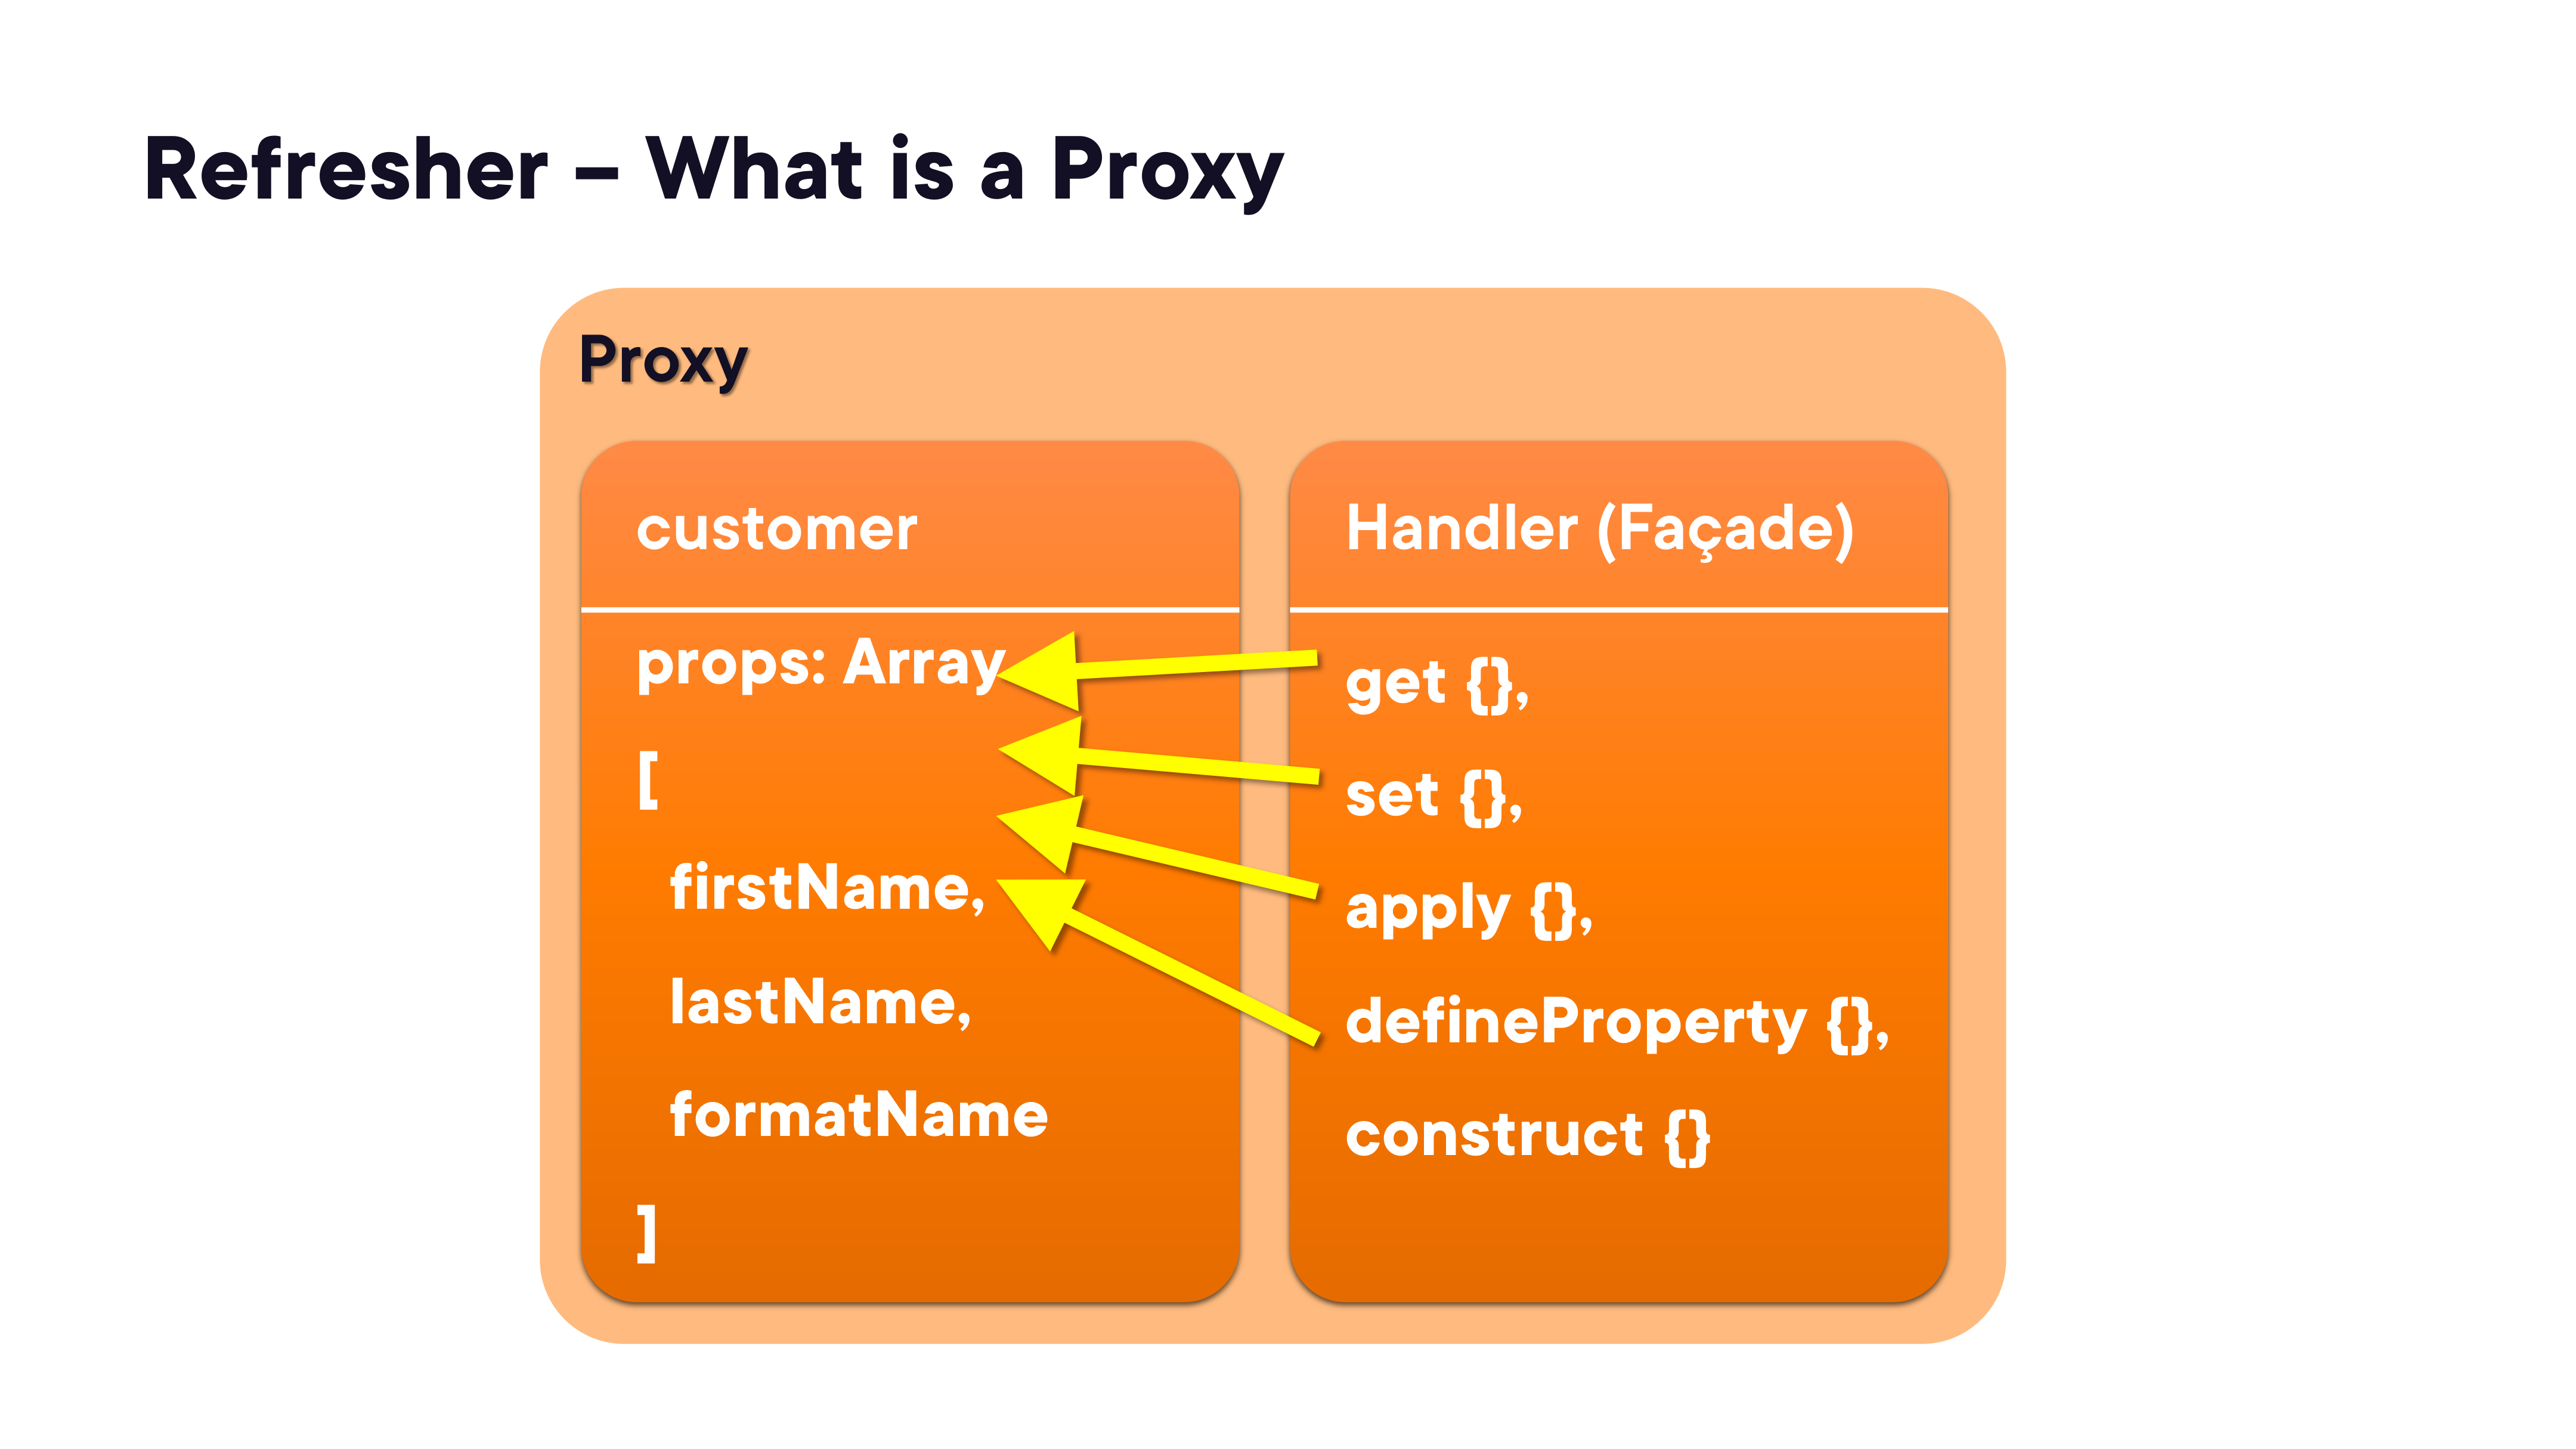

In [4]:
render_diagram(Path("assets/03-proxy-architecture.png"))

Each trap has a specific **required return type**. Returning the wrong type causes a `TypeError` at runtime:


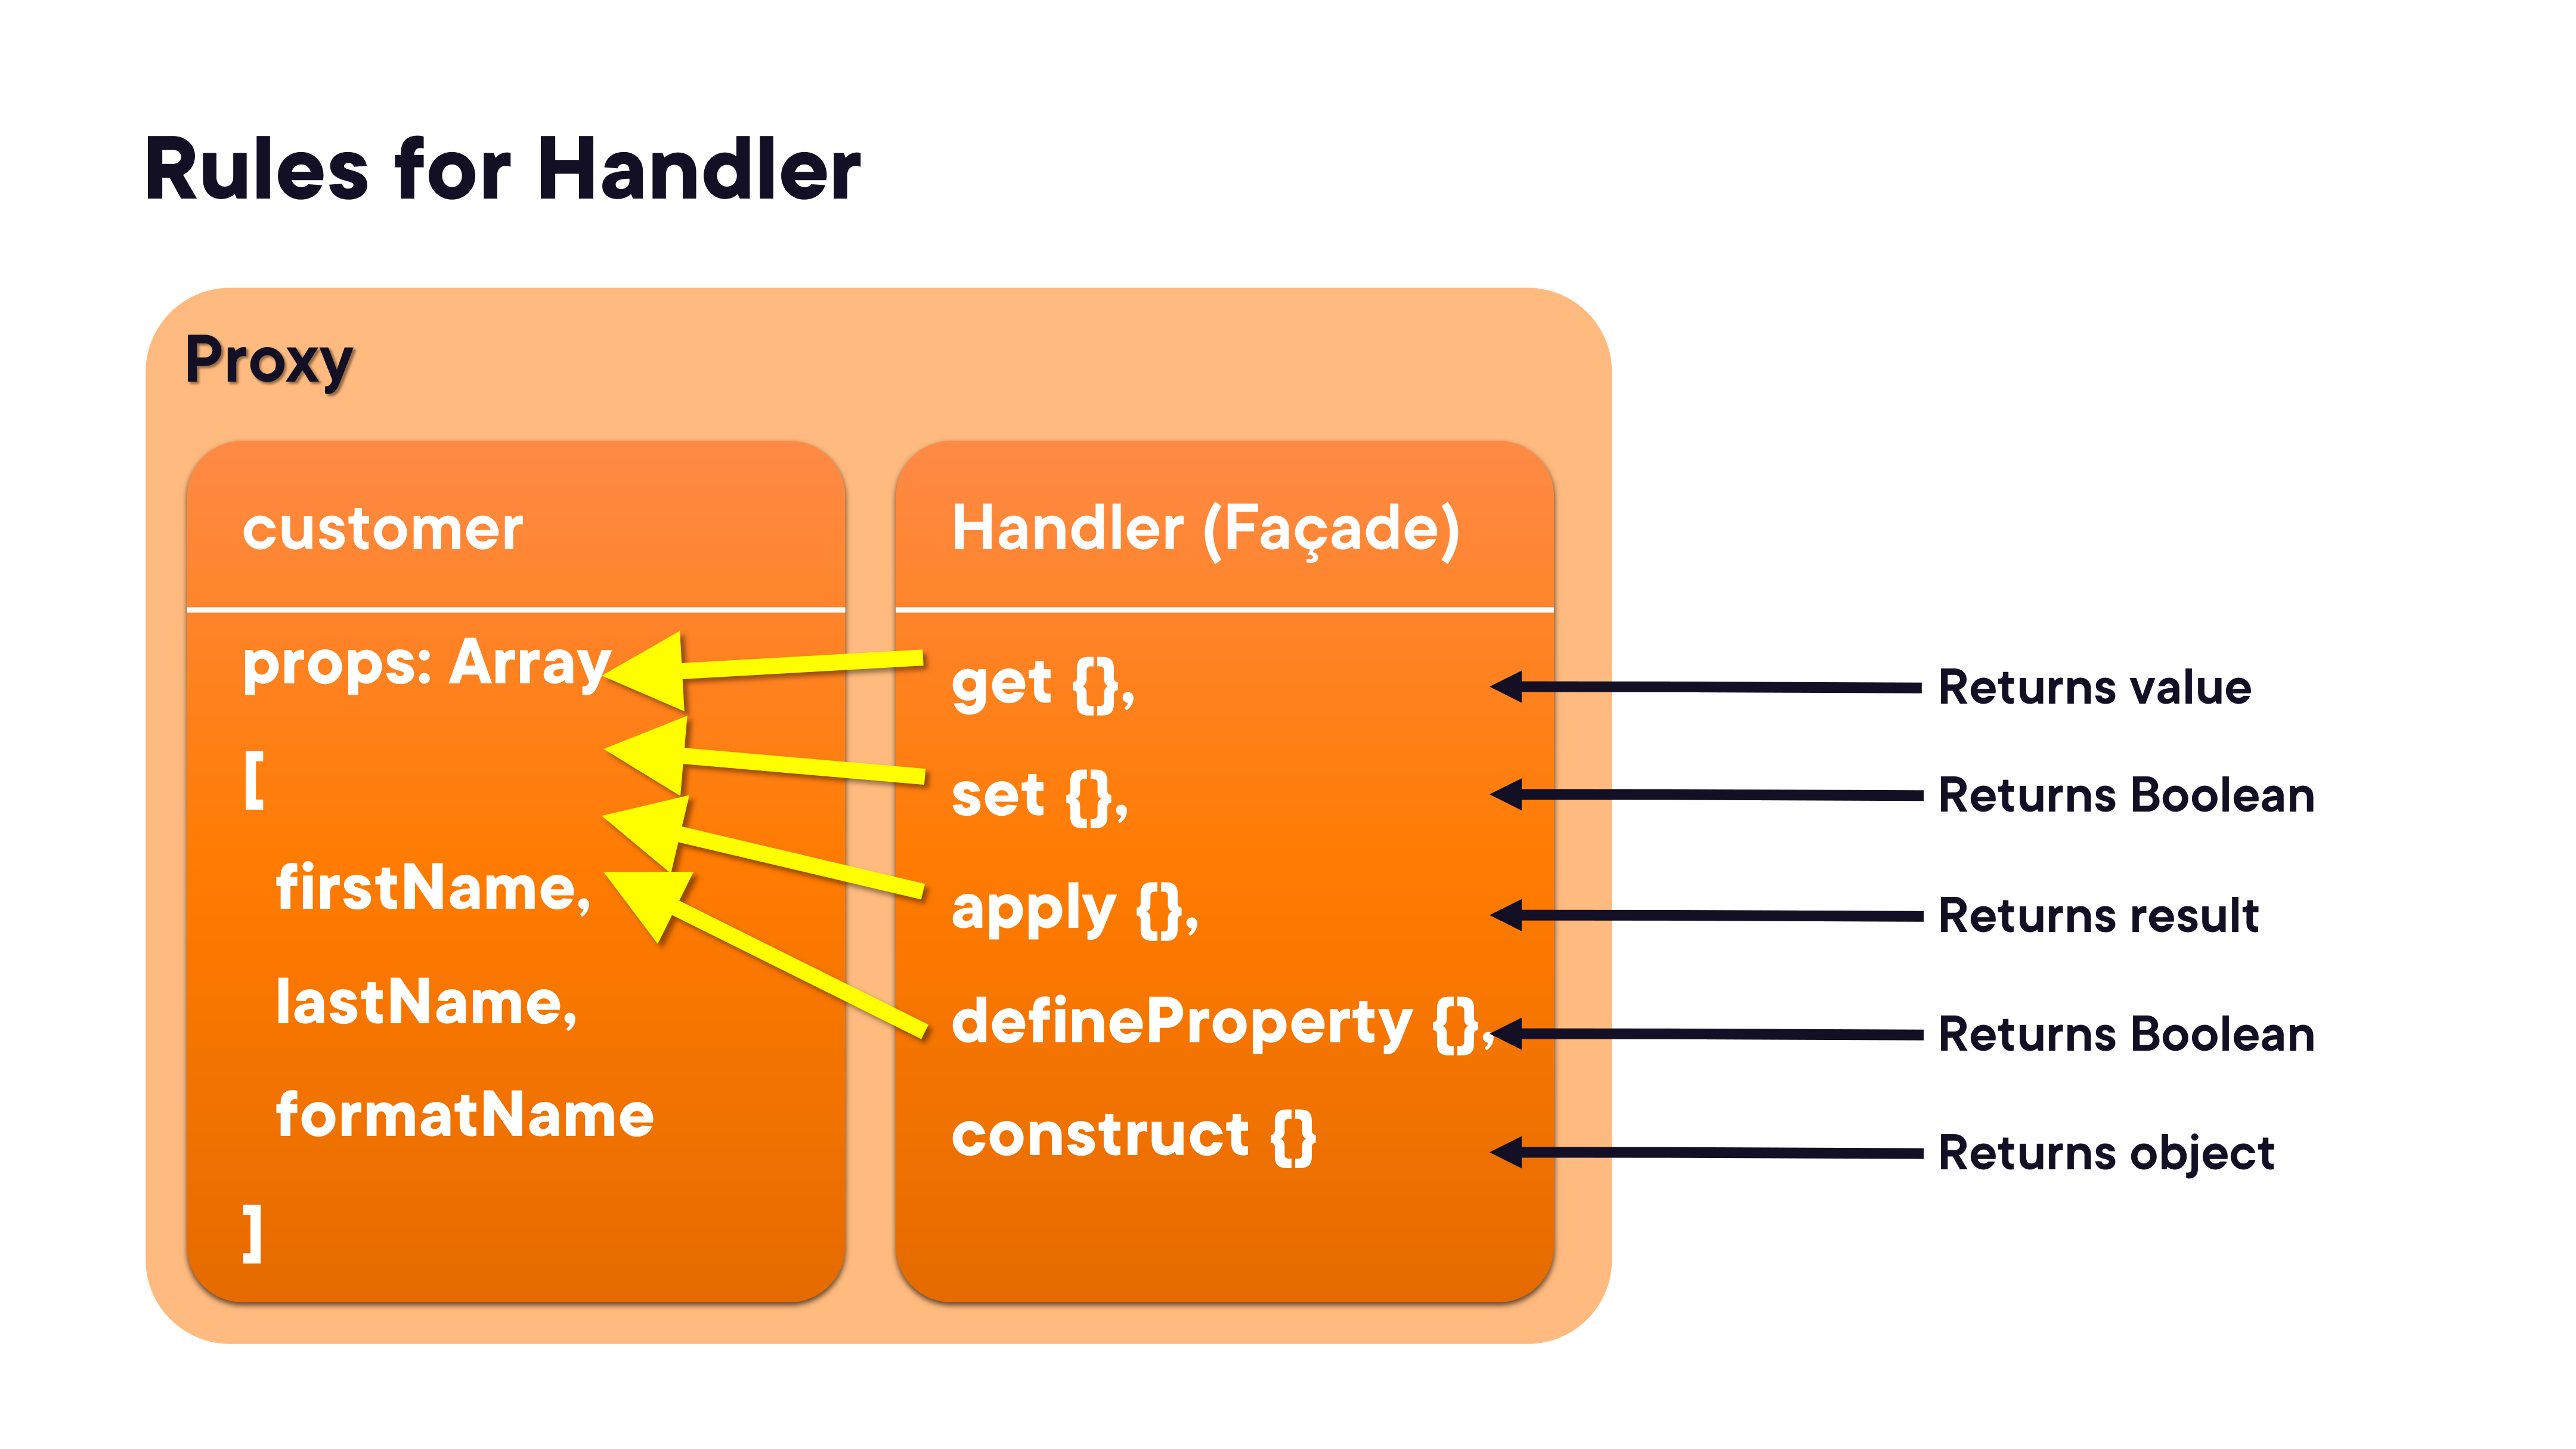

In [5]:
render_diagram(Path("assets/04-proxy-handler-return-types.png"))

### Why Use Reflect Inside a Proxy?

Without `Reflect`, delegating back to the target in a `get` trap looks like this:

```javascript
get(target, key) {
  return target[key]; // simple but loses receiver context
}
```

The problem arises with inherited getters: `target[key]` evaluates the getter with `target` as `this`, not the proxy. Using `Reflect.get` with the `receiver` argument fixes this:

```javascript
get(target, key, receiver) {
  return Reflect.get(target, key, receiver); // receiver = the proxy
}
```

`Reflect` also makes trap delegation **one-liners with spread**:

```javascript
const handler = {
  get()              { return Reflect.get(...arguments); },
  set()              { return Reflect.set(...arguments); },
  apply()            { return Reflect.apply(...arguments); },
  defineProperty()   { return Reflect.defineProperty(...arguments); },
};
```

This pattern keeps custom logic readable — add your code before or after the `Reflect` call, and delegation is handled automatically.

### Complete Example: Proxy + Reflect on a Class

This pattern from the demos shows a full production-style usage — wrapping a class so every instance is automatically proxied, with `Reflect` used throughout for correct delegation:

```javascript
// from 04-reflect-demos/after/Order.js
const handler = {
  get(target, key, receiver) {
    const result = Reflect.get(target, key, receiver);
    if (typeof result === "function") {
      // wrap methods so calls are logged
      return new Proxy(result, {
        apply() {
          console.log(`Calling ${key} Function`);
          return Reflect.apply(...arguments);
        }
      });
    }
    console.log(`getting key: ${key} = ${result}`);
    return result;
  },
  set(target, key, value) {
    const result = Reflect.set(target, key, value);
    if (!target.isValid()) {
      console.log("Target isn't valid");
    }
    return result;
  }
};

const typeHandler = {
  construct() {
    const result = Reflect.construct(...arguments);
    return new Proxy(result, handler); // every new Order() is wrapped
  }
};

export default new Proxy(Order, typeHandler);
```

Key points:
- The exported value is the proxied class — callers write `new Order()` unchanged
- Method calls are wrapped in a second proxy so `apply` can log them
- `set` validates the object after every property change
- All delegation uses `Reflect` to correctly forward `receiver` and argument lists

### Demo: Reflect in Practice

See [`04-reflect-demos/`](04-reflect-demos/) for the complete project. The `before/` directory shows the plain `Order` class; `after/Order.js` exports it wrapped in the full `typeHandler` + `handler` proxy chain using `Reflect` throughout.

### Module 04 Summary

> `Reflect` can simplify proxy handlers by providing one-liner delegation that correctly handles `receiver` context. While `Reflect` can be used outside a proxy, it is rare to do so. The more your proxy does, the slower it will run — keep handler logic minimal.